# Miniproyecto 3: Clasificación de animales

## Entrega 2
En esta entrega, nos enfocaremos en aprender a utilizar nuestros dos primeros descriptores y en implementar nuestro primer clasificador. En particular, trabajaremos con el clasificador de K Vecinos Más Cercanos (K-NN). Los descriptores que utilizaremos en esta ocasión son: Descriptores de color y Descriptores de textura.

Es importante entender que no todas las formas de representar las imágenes son igualmente efectivas para la tarea de clasificación. El objetivo es encontrar la representación más adecuada de las imágenes, aquella que permita una clasificación precisa y eficiente. Para lograr esto, debemos probar y evaluar distintos tipos de descriptores.

En cuanto a los clasificadores, el clasificador de K Vecinos Más Cercanos (K-NN) es un algoritmo intuitivo y respaldado teóricamente, pero presenta algunas limitaciones. Una de las principales desventajas es que es muy sensible al tipo de distancia que utilicemos entre los puntos (o vectores de características) y también a la presencia de outliers en los datos. Además, K-NN es computacionalmente costoso, especialmente cuando trabajamos con grandes conjuntos de datos, ya que requiere comparar cada punto con todos los demás durante el proceso de clasificación.

### Preliminares
Copie las funciones necesarias de la entrega pasada en las siguientes celdas.

In [1]:
# Importar librerias importantes
import os
import random
import pickle
import numpy as np
from tqdm import tqdm
from glob import glob
from matplotlib import pyplot as plt

from scipy.signal import correlate2d
from scipy.io import loadmat

import cv2

from sklearn.metrics import precision_recall_fscore_support
from sklearn.cluster import KMeans
from sklearn.neighbors import KNeighborsClassifier

In [2]:
group = None # Cambiar por el número de grupo
# YOUR CODE HERE (Daniela)
group = 19 # Número de grupo asignado en Bloque Neón (el mismo de la Entrega 1)

In [3]:
def determine_classes(group: int) -> list:
    """Función que determina las clases a utilizar en el proyecto.

    Args:
        group (int): Número de grupo.

    Returns:
        list: Lista con los nombres de las clases a utilizar.
    """
    # Se fija la semilla para reproducibilidad
    random.seed(group)
    
    # Se obtienen las categorías y la cantidad de imágenes por categoría
    stats = [('Canis latrans', 1286), ('Castor canadensis', 854), ('Dasypus novemcinctus', 515), ('Didelphis virginiana', 713), 
             ('Lepus californicus', 515), ('Lynx rufus', 854), ('Megaptera novaeangliae', 515), ('Mephitis mephitis', 515), 
             ('Odocoileus hemionus', 1286), ('Odocoileus virginianus', 1795), ('Otospermophilus beecheyi', 854), 
             ('Otospermophilus variegatus', 515), ('Phoca vitulina', 713), ('Procyon lotor', 1286), ('Sciurus carolinensis', 1795), 
             ('Sciurus niger', 1795), ('Sylvilagus audubonii', 515), ('Sylvilagus floridanus', 854), ('Tamias striatus', 854), 
             ('Tamiasciurus hudsonicus', 713), ('Urocyon cinereoargenteus', 515), ('Ursus americanus', 713), ('Vulpes vulpes', 854)]
    
    # Se agrupan las categorías por cantidad de imágenes
    clusters = {}
    for category, num_images in stats:
        if num_images in clusters:
            clusters[num_images].append(category)
        else:
            clusters[num_images] = [category]
    
    # Se selecciona una categoría aleatoria de cada cluster
    categories = []
    for cluster_categories in clusters.values():
        categories += [random.choice(cluster_categories)]
    return categories

assert group is not None, "Por favor, asigna un número de grupo a la variable 'group'."
assert group > 0, "El número de grupo debe ser mayor que 0."
assert group <= 28, "El número de grupo debe ser menor o igual que 28."

categories = determine_classes(group)
print(f"Las classes que usarán en este Mini-proyecto serán:\n{", ".join(categories)}.")

Las classes que usarán en este Mini-proyecto serán:
Procyon lotor, Castor canadensis, Urocyon cinereoargenteus, Didelphis virginiana, Sciurus niger.


In [4]:
dict_labels = {} # Cambiar por un diccionario con las etiquetas de las clases

# YOUR CODE HERE (Daniela)
# Carpeta con los datos (train, valid y test), al mismo nivel que este notebook
DATA_DIR = "dataset"

# Se ordenan las clases alfabéticamente y se les asigna un ID empezando en 0
dict_labels = {name: i for i, name in enumerate(sorted(categories))}

def get_data(subset: str) -> tuple[list[str], list[int]]:
  """Función que obtiene las rutas de las imágenes y sus etiquetas.

  Args:
      subset (str): Nombre del subconjunto de datos a utilizar.

  Returns:
      tuple[list, list]: Rutas de las imágenes y sus etiquetas.
  """
  paths = []
  labels = []

  # YOUR CODE HERE (Daniela)
  # Solo se recorren las clases asignadas al grupo
  for name, idx in dict_labels.items():
      # Rutas de todas las imágenes de esta clase en el subset
      class_paths = sorted(glob(os.path.join(DATA_DIR, subset, name, "*")))
      paths += class_paths
      # Cada imagen recibe el ID de su clase
      labels += [idx] * len(class_paths)
  return paths, labels

train_paths, train_labels = get_data("train")
valid_paths, valid_labels = get_data("valid")
test_paths, test_labels = get_data("test")

In [5]:
assert len(train_paths) > 0, "No se ha cargado ningún dato de entrenamiento"
assert len(train_paths) == 5163, "El número de datos de entrenamiento no es correcto"
assert len(valid_paths) > 0, "No se ha cargado ningún dato de validación"
assert len(valid_paths) == 1723, "El número de datos de validación no es correcto"
assert len(test_paths) > 0, "No se ha cargado ningún dato de test"
assert len(test_paths) == 1724, "El número de datos de test no es correcto"

assert type(train_paths[0]) == str, "Los datos de entrenamiento no tienen la forma correcta"
assert type(valid_paths[0]) == str, "Los datos de validación no tienen la forma correcta"
assert type(test_paths[0]) == str, "Los datos de test no tienen la forma correcta"

assert type(train_labels[0]) == int, "Las etiquetas de entrenamiento no tienen la forma correcta"
assert type(valid_labels[0]) == int, "Las etiquetas de validación no tienen la forma correcta"
assert type(test_labels[0]) == int, "Las etiquetas de test no tienen la forma correcta"

assert len(dict_labels) == len(categories), "El diccionario de labels no tiene la longitud correcta"

categories_sorted = sorted(categories)
assert list(dict_labels.keys()) == categories_sorted, "Las llaves del diccionario de labels no son correctas"
assert list(dict_labels.values()) == list(range(len(categories))), "Los valores del diccionario de labels no son correctos"

assert min([dict_labels[train_paths[i].split(os.sep)[-2]] == train_labels[i] for i in range(len(train_paths))]), "Las etiquetas de entrenamiento no coinciden"
assert min([dict_labels[valid_paths[i].split(os.sep)[-2]] == valid_labels[i] for i in range(len(valid_paths))]), "Las etiquetas de validación no coinciden"
assert min([dict_labels[test_paths[i].split(os.sep)[-2]] == test_labels[i] for i in range(len(test_paths))]), "Las etiquetas de test no coinciden"

In [6]:
def processing(Im: np.ndarray, img_size: tuple[int] | None = None, color_space: str | None = None) -> np.ndarray:
    """Función que preprocesa una lista de imágenes.

    Args:
        Im_list (list[np.ndarray]): Lista con las imágenes a preprocesar.
        img_size (tuple[int] | None): Tamaño de la imagen.
        color_space (str | None): Espacio de color a utilizar. Puede ser "rgb", "gray", "hsv" o "lab".

    Returns:
        list[np.ndarray]: Lista con las imágenes preprocesadas.
    """

    # YOUR CODE HERE (Daniela)
    # Redimensionar solo si se da un tamaño
    if img_size is not None:
        Im = cv2.resize(Im, img_size)

    # Convertir de BGR al espacio de color pedido (si se da uno)
    if color_space is not None:
        conversions = {
            "rgb": cv2.COLOR_BGR2RGB,
            "gray": cv2.COLOR_BGR2GRAY,
            "hsv": cv2.COLOR_BGR2HSV,
            "lab": cv2.COLOR_BGR2LAB,
        }
        Im = cv2.cvtColor(Im, conversions[color_space])

    return Im

In [7]:
Im_list = [cv2.imread(path) for path in train_paths[:5]]
img_size = (224, 224)
color_space = "rgb"
Im_proc = [processing(Im, img_size, color_space) for Im in Im_list]

assert len(Im_proc) == len(Im_list), "El número de imágenes preprocesadas no es correcto"
assert type(Im_proc) == list, "Las imágenes preprocesadas no están en una lista"
assert type(Im_proc[0]) == np.ndarray, "Las imágenes preprocesadas no son arreglos de numpy"
assert np.array(Im_proc).shape[1:] == (224, 224, 3), "Las imágenes preprocesadas no tienen el tamaño correcto"
assert np.array_equal(cv2.cvtColor(cv2.resize(Im_list[0], (224, 224)), cv2.COLOR_BGR2RGB), Im_proc[0]), "Las imágenes preprocesadas no son correctas"

color_space = "gray"
Im_proc = [processing(Im, img_size, color_space) for Im in Im_list]
assert np.array(Im_proc).shape[1:] == (224, 224), "Las imágenes preprocesadas no tienen el tamaño correcto"
assert np.array_equal(cv2.cvtColor(cv2.resize(Im_list[0], (224, 224)), cv2.COLOR_BGR2GRAY), Im_proc[0]), "Las imágenes preprocesadas no son correctas"

color_space = "hsv"
Im_proc = [processing(Im, img_size, color_space) for Im in Im_list]
assert np.array(Im_proc).shape[1:] == (224, 224, 3), "Las imágenes preprocesadas no tienen el tamaño correcto"
assert np.array_equal(cv2.cvtColor(cv2.resize(Im_list[0], (224, 224)), cv2.COLOR_BGR2HSV), Im_proc[0]), "Las imágenes preprocesadas no son correctas"

color_space = "lab"
Im_proc = [processing(Im, img_size, color_space) for Im in Im_list]
assert np.array(Im_proc).shape[1:] == (224, 224, 3), "Las imágenes preprocesadas no tienen el tamaño correcto"
assert np.array_equal(cv2.cvtColor(cv2.resize(Im_list[0], (224, 224)), cv2.COLOR_BGR2LAB), Im_proc[0]), "Las imágenes preprocesadas no son correctas"

Im_proc = [processing(Im, (256, 256)) for Im in Im_list]
assert np.array(Im_proc).shape[1:] == (256, 256, 3), "Las imágenes preprocesadas no tienen el tamaño correcto"
assert np.array_equal(cv2.resize(Im_list[0], (256, 256)), Im_proc[0]), "Las imágenes preprocesadas no son correctas"

Im_proc = [processing(Im, None, "lab") for Im in Im_list]
assert np.array_equal(cv2.cvtColor(Im_list[0], cv2.COLOR_BGR2LAB), Im_proc[0]), "Las imágenes preprocesadas no son correctas"

### Parte 1: Histogramas
La representación de una imagen mediante su color puede hacerse de diversas maneras. La forma más común es usar histogramas de color, ya sea concatenados o conjuntos, para describir la distribución de colores en una imagen. Estos métodos estadísticos ya los hemos utilizado en el pasado, y para nuestro primer enfoque de clasificación usaremos un enfoque basado en histogramas de color. Sin embargo, es importante tener en cuenta que este método tiene limitaciones, ya que en ocasiones los colores de los animales o las escenas entre diferentes categorías pueden ser similares.

#### Parte 1.1: Color
Instrucciones:

1. Implementa una función que reciba una imagen de entrada y una cantidad específica de bins y retorne su histograma de color. El histograma puede ser:

    - Conjunto: Un histograma donde se consideren todas las combinaciones posibles de los canales de color (es decir, un histograma en un espacio tridimensional en el caso de RGB o Lab).
    - Concatenado: Un histograma independiente por cada canal de color, concatenando los histogramas de cada canal en un solo vector.

2. Retorno: El histograma debe estar normalizado, es decir, los valores deben estar escalados para que la suma total sea 1.

**Nota:** Pueden tomar la implementación del tutorial de la semana 11.

In [8]:
def color_hist(Im: np.ndarray, type_h: str, bins: int) -> np.ndarray:
    """Función que calcula el histograma de color conjunto o concatenado de una imagen

    Args:
        Im (numpy.ndarray): Imagen a la que calcular el histograma
        type_h (str): Tipo de histograma a calcular, puede ser "concat" o "joint"
        bins (int): Cantidad de bins que usar en el histograma. En el caso de concat el número de bins finale será 3*bins
        En el caso de Joint será bins^3

    Returns:
        numpy.ndarray: Histograma de color normalizado
    """
    h = "" # Histograma de color normalizado
    # YOUR CODE HERE (Daniela)
    # Como en el tutorial de la semana 11, el rango de los bins va del mínimo al máximo de cada canal
    if type_h == "concat":
        # Un histograma por cada canal y luego se ponen uno detrás del otro
        h = np.concatenate([np.histogram(Im[:, :, c], bins=bins)[0] for c in range(3)])
    elif type_h == "joint":
        # Un solo histograma 3D con todas las combinaciones de los 3 canales, luego se aplana
        h = np.histogramdd(Im.reshape(-1, 3), bins=bins)[0].flatten()

    # Se normaliza para que la suma total sea 1
    h = h / np.sum(h)
    return h

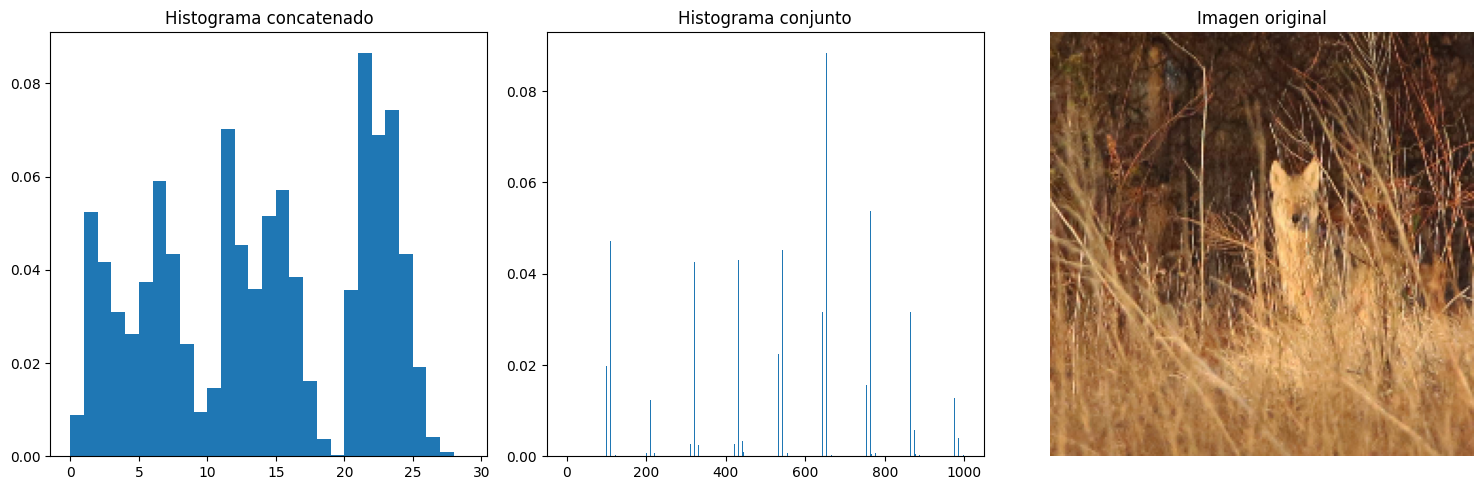

In [9]:
img=processing(cv2.imread(os.path.join(".", "dataset", "train", "Canis latrans", "f494fab00ebb2d87c8d3bf5215560d54.jpg")),  (224, 224), 'rgb')
concat_h=color_hist(img,'concat',10)
joint_h=color_hist(img,'joint',10)


fig,ax=plt.subplots(1,3,figsize=(15,5))
ax[0].hist(list(range(len(concat_h))), list(range(len(concat_h - 1))), weights = concat_h)
ax[0].set_title('Histograma concatenado')
ax[1].hist(list(range(len(joint_h))), list(range(len(joint_h - 1))), weights = joint_h)
ax[1].set_title('Histograma conjunto')
ax[2].imshow(img)
ax[2].axis('off')
ax[2].set_title('Imagen original')

plt.tight_layout()

assert np.isclose(np.sum(concat_h),1,0.1), 'Su histograma concatenado no esta normalizado'
assert np.isclose(np.sum(joint_h),1,0.1), 'Su histograma conjunto no esta normalizado'
assert len(concat_h.shape)==1 and len(joint_h.shape)==1, 'Su histograma debe tener una unica dimension'
assert np.isclose(len(concat_h)/3,len(joint_h)**(1/3),0.01),' Sus histogramas no tienen la cantidad de bins que deberían'
assert np.isclose(np.std(concat_h),0.024,0.05), 'Su histograma de color concatenado es erroneo'
assert np.isclose(np.std(joint_h),0.0063,0.05), 'Su histograma de color conjunto es erroneo'

#### Parte 1.2: Entrenamiento
Ahora que contamos con nuestra función para calcular los histogramas (también conocidos como descriptores) de una imagen, podemos utilizarlos para realizar la clasificación de las imágenes. Para ello, necesitamos dos componentes clave: los descriptores y un clasificador.

Proceso de extracción de descriptores:

1. Cálculo de histogramas:

    - Para cada imagen seleccionada, calcula tanto el histograma conjunto como el histograma concatenado.
    - Guarda las etiquetas (labels) correspondientes a cada imagen en otra variable. Asegúrate de que cada imagen tenga su histograma y etiqueta asociados.
    
    Nota: La cantidad de bins para los histogramas deben ser seleccionados según tu criterio. Es posible que al usar un número reducido de imágenes de entrenamiento no observes una gran diferencia entre los diferentes espacios de color. Recuerden utilizar su función de procesamiento para estandarizar las imágenes.

2. Imágenes de validación:

    - Aplica el mismo procedimiento de cálculo de histogramas a todas las imágenes del conjunto de validación (valid). Asegúrate de calcular los histogramas y guardar las etiquetas correspondientes de la misma forma que hiciste con las imágenes de entrenamiento.

Puntos importantes:

- Recuerda que la cantidad de bins afecta el desempeño. Puedes experimentar con diferentes configuraciones para observar cómo influyen en la clasificación.

In [10]:
train_images_num='' #cantidad de imagens de entrenamiento
train_joint_color_desc=[] #Descriptor de imagenes con histogramas conjuntos de color
train_concat_color_desc=[] #Descriptor de imagenes con histogramas concatenados de color

valid_joint_color_desc=[] #Descriptor de imagenes con histogramas conjuntos de color
valid_concat_color_desc=[] #Descriptor de imagenes con histogramas concatenados de color

# YOUR CODE HERE (Daniela)
color_space = "hsv" # Espacio de color elegido
bins = 10                 # Bins por canal (concat: 3*bins, joint: bins^3)
img_size = (224, 224)          # Tamaño estándar de las imágenes

# Se usan todas las imágenes de entrenamiento
train_images_num = len(train_paths)

# Descriptores de entrenamiento (las etiquetas van en el mismo orden que las rutas)
for path in tqdm(train_paths[:train_images_num], desc="Train"):
    Im = processing(cv2.imread(path), img_size, color_space)
    train_joint_color_desc.append(color_hist(Im, "joint", bins))
    train_concat_color_desc.append(color_hist(Im, "concat", bins))
train_color_labels = train_labels[:train_images_num]

# Descriptores de validación, con el mismo procedimiento
for path in tqdm(valid_paths, desc="Valid"):
    Im = processing(cv2.imread(path), img_size, color_space)
    valid_joint_color_desc.append(color_hist(Im, "joint", bins))
    valid_concat_color_desc.append(color_hist(Im, "concat", bins))
valid_color_labels = valid_labels

Valid: 100%|██████████| 1723/1723 [01:23<00:00, 20.67it/s]


In [11]:
assert len(train_joint_color_desc) == 5163, 'La cantidad de descriptores no es igual a la cantidad de imágenes totales'
assert len(train_concat_color_desc) == 5163, 'La cantidad de descriptores no es igual a la cantidad de imágenes totales'
assert len(valid_joint_color_desc) == 1723, 'La cantidad de descriptores no es igual a la cantidad de imágenes totales'
assert len(valid_concat_color_desc) == 1723, 'La cantidad de descriptores no es igual a la cantidad de imágenes totales'

assert len(train_joint_color_desc[0])<= 7056, 'Su descriptor unimodal de color tiene demasiadas dimensiones'
assert len(train_concat_color_desc[0])<= 7056, 'Su descriptor unimodal de color tiene demasiadas dimensiones'
assert len(train_joint_color_desc[0]) == len(train_joint_color_desc[0]), 'Los descriptores conjuntos tienen diferentes dimensiones'
assert len(train_concat_color_desc[0]) == len(valid_concat_color_desc[0]), 'Los descriptores concatenados tienen diferentes dimensiones'

Ahora que hemos calculado los descriptores para varias imágenes y utilizaremos el clasificador [KNeighborsClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsClassifier.html) para realizar el entrenamiento con los descriptores y etiquetas del conjunto de entrenamiento (train). El clasificador de K vecino más cercano debería ser un concepto familiar para ustedes a este punto. Sin embargo, repasemos brevemente su funcionamiento. El clasificador de vecino más cercano compara un nuevo dato (descriptor) con todos los datos de entrenamiento y le asigna la etiqueta de la clase predominante dentro de los K vecinos más cercanos. Luego, utilizaremos los descriptores del conjunto de validación (valid) para predecir las etiquetas correspondientes. Finalmente, evaluaremos qué tan buenos son nuestros resultados.

**Proceso:**
1. Construcción de clasificadores:

    - Crea un objeto del tipo KNeighborsClassifier para cada uno de los dos tipos de descriptores calculados (histograma conjunto e histograma concatenado).

2. Entrenamiento:

    - Utiliza el método .fit de cada modelo para entrenar los clasificadores con los descriptores y las etiquetas del conjunto de entrenamiento.

3. Predicción:

    - Aplica el método .predict a los descriptores del conjunto de validación para cada uno de los modelos (histograma conjunto y concatenado) y obtén las etiquetas predichas.

In [12]:
NNClassifier_concatcolor='' # Clasificador con histogramas concatenados de color
NNClassifier_jointcolor='' # Clasificador con histogramas conjuntos de color

predict_NNClassifier_concatcolor = '' # Predicciones del clasificador con histogramas concatenados de color
predict_NNClassifier_jointcolor = '' # Predicciones del clasificador con histogramas conjuntos de color

# YOUR CODE HERE (Daniela)
k = 5 # Cantidad de vecinos

# 1. Se crea un clasificador K-NN para cada tipo de histograma
NNClassifier_concatcolor = KNeighborsClassifier(n_neighbors=k)
NNClassifier_jointcolor = KNeighborsClassifier(n_neighbors=k)

# 2. Se entrenan con los descriptores y etiquetas de entrenamiento
NNClassifier_concatcolor.fit(train_concat_color_desc, train_color_labels)
NNClassifier_jointcolor.fit(train_joint_color_desc, train_color_labels)

# 3. Se predicen las etiquetas de validación
predict_NNClassifier_concatcolor = NNClassifier_concatcolor.predict(valid_concat_color_desc)
predict_NNClassifier_jointcolor = NNClassifier_jointcolor.predict(valid_joint_color_desc)

In [13]:
assert NNClassifier_concatcolor.n_samples_fit_ == 5163, 'No se entrenó el clasificador con histogramas concatenados de color'
assert NNClassifier_concatcolor.n_features_in_ > 0, 'No se entrenó el clasificador con histogramas concatenados de color'
assert NNClassifier_jointcolor.n_samples_fit_ == 5163, 'No se entrenó el clasificador con histogramas conjuntos de color'
assert NNClassifier_jointcolor.n_features_in_ > 0, 'No se entrenó el clasificador con histogramas conjuntos de color'
assert NNClassifier_concatcolor.classes_.shape[0] == len(categories), 'El clasificador con histogramas concatenados de color no tiene las clases correctas'
assert NNClassifier_jointcolor.classes_.shape[0] == len(categories), 'El clasificador con histogramas conjuntos de color no tiene las clases correctas'

assert len(predict_NNClassifier_concatcolor) == len(valid_concat_color_desc), 'El número de predicciones debe ser igual al número de descriptores de validación'
assert len(predict_NNClassifier_jointcolor) == len(valid_joint_color_desc), 'El número de predicciones debe ser igual al número de descriptores de validación'

Ahora que hemos entrenado nuestros modelos y obtenido las predicciones, evaluaremos su rendimiento utilizando las métricas de precisión, recall y f1-score.

Utilizaremos la función precision_recall_fscore_support de la librería sklearn.metrics para calcular estas métricas comparando las etiquetas reales con las predicciones.

**Instrucciones:**

1. Evaluación de los modelos:

    - Para cada modelo (histograma conjunto e histograma concatenado), aplica precision_recall_fscore_support para calcular las métricas de precisión, recall y f1-score, comparando las etiquetas verdaderas del conjunto de validación con las predicciones obtenidas.

2. Uso del parámetro average:

    - Si deseas obtener el promedio de las métricas, utiliza average="macro".
    - Si prefieres obtener las métricas individuales para cada categoría, utiliza average=None. Esto te devolverá las métricas por separado para cada categoría de animal.
    
Nota: Finalmente, compara los resultados obtenidos para ambos modelos y analiza cuál funciona mejor en función de las métricas calculadas.

In [14]:
precision_concatcolor = '' #Precision del clasificador con histogramas concatenados de color
recall_concatcolor = '' #Recall del clasificador con histogramas concatenados de color
f1_score_concatcolor = '' #F1 del clasificador con histogramas concatenados de color

precision_jointcolor = '' #Precision del clasificador con histogramas conjuntos de color
recall_jointcolor = '' #Recall del clasificador con histogramas conjuntos de color
f1_score_jointcolor = '' #F1 del clasificador con histogramas conjuntos de color

# YOUR CODE HERE (Daniela)
# Métricas promedio (macro) comparando las etiquetas reales de validación con las predichas
precision_concatcolor, recall_concatcolor, f1_score_concatcolor, _ = precision_recall_fscore_support(
    valid_color_labels, predict_NNClassifier_concatcolor, average="macro", zero_division=0)
precision_jointcolor, recall_jointcolor, f1_score_jointcolor, _ = precision_recall_fscore_support(
    valid_color_labels, predict_NNClassifier_jointcolor, average="macro", zero_division=0)

print ("{:<25} | {:<14} {:<14} {:<14}".format('Modelo','Precisión','Cobertura', 'F1'))
print ('----------------------------------------------------------------------')
print ("{:<25} | {:<14.3f} {:<14.3f} {:<14.3f}".format('Histograma concatenado',precision_concatcolor,recall_concatcolor,f1_score_concatcolor))
print ("{:<25} | {:<14.3f} {:<14.3f} {:<14.3f}".format('Histograma Conjunto',precision_jointcolor,recall_jointcolor,f1_score_jointcolor))

Modelo                    | Precisión      Cobertura      F1            
----------------------------------------------------------------------
Histograma concatenado    | 0.373          0.358          0.351         
Histograma Conjunto       | 0.356          0.344          0.336         


In [15]:
assert f1_score_concatcolor > 0.28, 'El modelo con histogramas concatenados de color debería tener una f-medida mayor'
assert f1_score_jointcolor > 0.28, 'El modelo con histogramas cnojuntos de color debería tener una f-medida mayor'

### Parte 2: Textura
En la sección anterior ya utilizamos el color como representación de nuestras imágenes. Dependiendo del problema, esta puede ser una representación válida, ya que algunos animales pueden ser fácilmente diferenciados por su color. Sin embargo, en muchos casos, animales de distintas categorías pueden compartir un color similar, o bien, animales de la misma categoría pueden tener colores muy diferentes.

Una alternativa interesante es utilizar un descriptor de textura para representar nuestras imágenes. La textura se refiere a patrones repetitivos dentro de las imágenes, como el pelaje de un animal o las escamas en la piel. Al capturar estos patrones, podemos encontrar una forma distinta y, en algunos casos, más efectiva de representar las imágenes para su clasificación.

En esta parte, aprenderemos cómo representar una imagen mediante su textura.

Primero implementaremos un código que selecciona aleatoriamente 25 imágenes del conjunto de entrenamiento. Esas 25 imágenes aleatorias las guardaras en una lista llamada Im_list. Además, para ser consistentes utilice la función `processing` para cambiar el tamaño de las imágenes a $256\times256$ y convertirla a escala de grises.

In [16]:
Im_list = '' #lista de imagenes, 5 de cada categoría
# YOUR CODE HERE (Daniela)
random.seed(group) # Semilla para que siempre salgan las mismas imágenes
Im_list = []
for name, idx in dict_labels.items():
    # Rutas de entrenamiento de esta clase
    class_paths = [p for p, l in zip(train_paths, train_labels) if l == idx]
    # Se eligen 5 al azar, se redimensionan a 256x256 y se pasan a gris
    for path in random.sample(class_paths, 5):
        Im_list.append(processing(cv2.imread(path), (256, 256), "gray"))

print(f"Cantidad de imágenes en Im_list: {len(Im_list)}")

Cantidad de imágenes en Im_list: 25


#### Parte 2.1: Respuesta a filtros

Para detectar los patrones repetitivos dentro de una imagen (como bordes, barras, puntos, etc.), utilizaremos la respuesta de la imagen a diferentes filtros. Se te proporcionará un banco de filtros que contiene varios tipos de patrones.

El archivo `.mat` que recibirás contiene una matriz de dimensiones 49x49x18, lo que significa que son 18 filtros de tamaño 49x49 cada uno.

Instrucciones:
1. Utiliza la función loadmat de scipy.io para leer el archivo .mat. Esta función devolverá un diccionario, y la llave "filterbank" te proporcionará la matriz con los filtros.

**Nota:** Revisen bien cómo utilizar loadmat para cargar el archivo y cómo acceder a la matriz de filtros. Esto será esencial para los próximos pasos del miniproyecto.



In [17]:
filterbank='' #arreglo de filtros
# YOUR CODE HERE (Daniela)
# loadmat devuelve un diccionario; la llave "filterbank" tiene la matriz 49x49x18
filterbank = loadmat("filterbank.mat")["filterbank"]
print(f"Tamaño del banco de filtros: {filterbank.shape}")

Tamaño del banco de filtros: (49, 49, 18)


Tu tarea ahora es crear una función que reciba por parámetro una imagen y el filterbank (en forma de array). La función debe aplicar cada uno de los N filtros del filterbank a la imagen de entrada, donde N es la cantidad de filtros presentes en el filterbank.

El resultado final debe ser una imagen con N canales, donde cada canal corresponde a la respuesta de la imagen a uno de los filtros. El tamaño de cada canal debe ser el mismo que el de la imagen original.

Instrucciones:
1. Utiliza la función correlate2d para realizar el filtrado de la imagen con cada filtro.
2. Importante: Asegúrate de verificar si la imagen está en escala de grises y si es necesario convertirla, ya que la respuesta de los filtros está diseñada para imágenes en gris.
4. Al final, combina las respuestas de todos los filtros en una sola imagen con N canales.

**Consejo:** `correlate2d` es una función de scipy.signal que te permitirá realizar la correlación de la imagen con cada filtro. Usando el modo "same", te asegurarás de que la salida de cada filtro tenga las mismas dimensiones que la imagen original.

In [18]:
def filter_map(Im: np.ndarray, filterbank: np.ndarray) -> np.ndarray:
    """Funcion que aplica un banco de filtros a una imagen

    Args:
        Im (numpy.ndarray): Imagen de entrada RGB
        filterbank (numpy.ndarray): Banco de filtros

    Returns:
        numpy.ndarray: Resultado de aplicar el banco de filtros a la imagen
    """
    new_im = '' #Imagen con los filtros aplicados
    # YOUR CODE HERE (Daniela)
    # Si la imagen está a color (3 canales) se pasa a escala de grises
    if len(Im.shape) == 3:
        Im = cv2.cvtColor(Im, cv2.COLOR_BGR2GRAY)

    # Se aplica cada filtro; "same" mantiene el tamaño de la imagen original
    responses = []
    for i in range(filterbank.shape[2]):
        responses.append(correlate2d(Im, filterbank[:, :, i], mode="same"))

    # Se juntan las N respuestas como los N canales de una sola imagen
    new_im = np.stack(responses, axis=2)
    return new_im

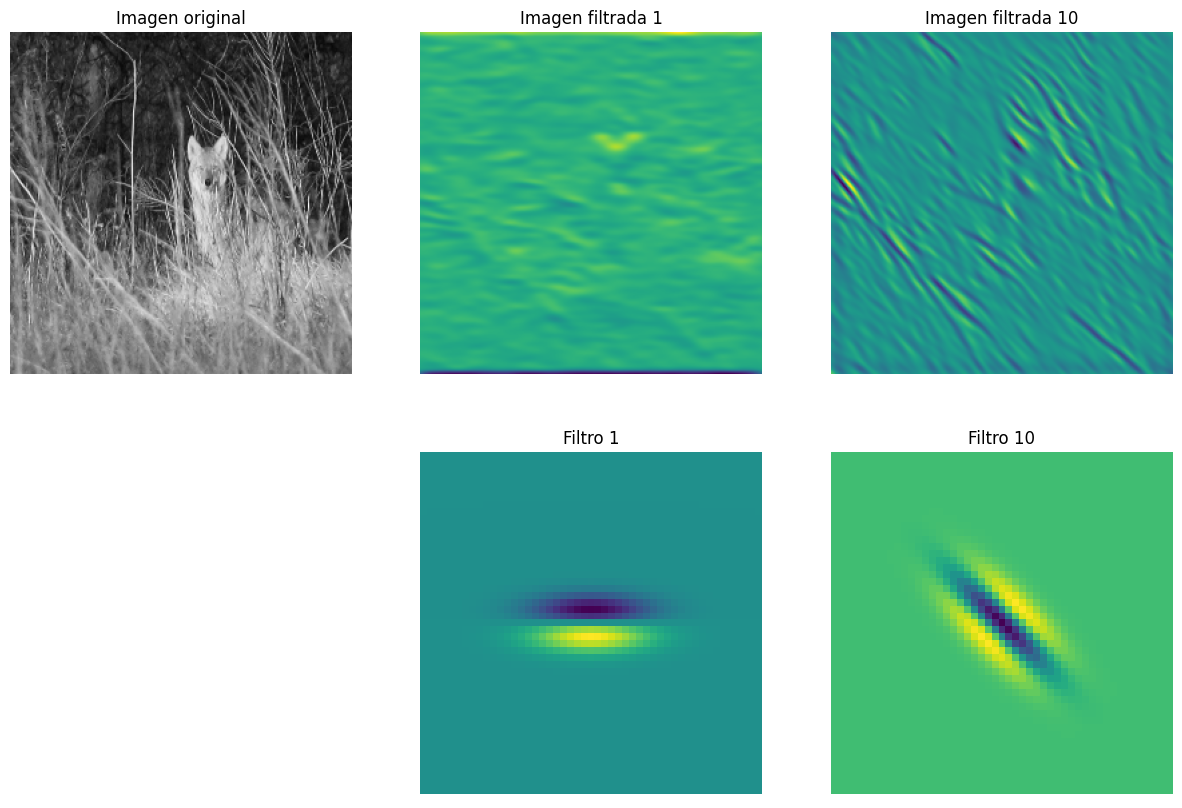

In [19]:
img=processing(cv2.imread(os.path.join(".", "dataset", "train", "Canis latrans", "f494fab00ebb2d87c8d3bf5215560d54.jpg")), (256, 256), 'gray')
new_img=filter_map(img,filterbank)

x,y=img.shape
x2,y2,f=new_img.shape
a,b,f2=filterbank.shape

assert f2==f, 'La imagen resultante debe tener la misma cantidad de canales como filtros en el filterbank'
assert x==x2 and y==y2, 'Las dimensiones de la imagen original no deben cambiar'
assert np.sum(np.std(new_img,axis=2))!=0, 'Usted usó el mismo filtro para todas las dimensiones'

assert np.sum(new_img[:,:,0]-correlate2d(img,filterbank[:,:,0],'same'))==0, 'El primer canal de new_im no es el resultado del filtrado con el primer filtro'
assert np.sum(new_img[:,:,2]-correlate2d(img,filterbank[:,:,2],'same'))==0, 'El primer canal de new_im no es el resultado del filtrado con el tercer filtro'

try:
    img_1=cv2.resize(cv2.imread(os.path.join(".", "dataset", "train", "Canis latrans", "f494fab00ebb2d87c8d3bf5215560d54.jpg")), (256, 256))
    filter_map(img_1,filterbank)
except:
    assert False, 'Su función debe funcionar con imágenes a color'

fig,ax=plt.subplots(2,3,figsize=(15,10))
ax[0,0].set_title('Imagen original')
ax[0,0].imshow(img, cmap='gray')
ax[0,1].set_title('Imagen filtrada 1')
ax[0,1].imshow(new_img[:,:,0])
ax[0,2].set_title('Imagen filtrada 10')
ax[0,2].imshow(new_img[:,:,9])

ax[0,0].axis('off')
ax[0,1].axis('off')
ax[0,2].axis('off')

ax[1,1].imshow(filterbank[:,:,0])
ax[1,1].set_title('Filtro 1')
ax[1,2].imshow(filterbank[:,:,9])
ax[1,2].set_title('Filtro 10')

ax[1,0].axis('off')
ax[1,1].axis('off')
ax[1,2].axis('off')

plt.show()

#### Parte 2.2: Colección de pixeles

Ya hemos creado una función que calcula la respuesta de una imagen a los filtros de un banco de filtros. Sin embargo, por sí sola, esta información aún no es suficiente. Recordemos que las texturas son patrones repetitivos en una imagen, y nuestro objetivo es identificar esos patrones. Pero, como seres humanos, no siempre podemos definir exactamente qué constituye un patrón repetitivo ni cuántos patrones hay en una imagen. Por lo tanto, dejaremos que la computadora defina y agrupe estos patrones por nosotros.

Utilizaremos el algoritmo de KMeans para agrupar los patrones de textura presentes en la imagen. Para ello, usaremos la respuesta de cada píxel a los filtros como datos de entrada para el algoritmo.

**Proceso:**
1. Datos de entrenamiento: Los datos de entrada para KMeans serán las respuestas de cada píxel a los N filtros aplicados en la parte anterior. Es decir, cada píxel será representado como un vector de tamaño N, donde cada valor corresponde a la respuesta del píxel a un filtro específico.

2. KMeans: Aplicaremos el algoritmo de KMeans para agrupar los píxeles en diferentes clústeres de texturas. El número de clústeres que escojamos corresponderá a la cantidad de texturas que la computadora identificará en la imagen.

##### Parte 2.2.1: Pixel dataset

Crea una función que reciba una lista de imágenes junto con el filterbank. Esta función debe realizar los siguientes pasos:

1. Obtener el mapa de respuesta a los filtros para cada imagen. Utiliza la función previamente implementada que aplica los filtros a la imagen y genera un mapa de respuesta.

2. Extraer los píxeles del mapa de respuesta: De cada imagen, extrae los valores de cada píxel a través de los N canales (donde N es el número de filtros en el filterbank). Cada píxel se convertirá en un vector de N dimensiones.

3. Agregar los píxeles a una lista: Crea una lista donde cada elemento será uno de los píxeles extraídos con sus N canales.

**Ejemplo:**
- Si tu imagen es de tamaño 256x256 y aplicas 18 filtros, el mapa de respuesta tendrá un tamaño de 256x256x18, lo que significa que tendrás 65536 píxeles, cada uno representado por un vector de 18 dimensiones.
- Si tienes 5 imágenes de tamaño 256x256, al final tendrás 327,680 píxeles, cada uno con 18 dimensiones.

Nota: Asegúrate de que todas tus imágenes tengan un tamaño de 256x256 antes de aplicar los filtros. Puedes redimensionarlas si es necesario.

In [20]:
# YOUR CODE HERE (Daniela)
def pixel_dataset(Im_list: list[np.ndarray], filterbank: np.ndarray) -> np.ndarray:
    """Función que junta los píxeles de varias imágenes, cada uno con su respuesta a los filtros.

    Args:
        Im_list (list[np.ndarray]): Lista de imágenes (256x256)
        filterbank (numpy.ndarray): Banco de filtros

    Returns:
        numpy.ndarray: Arreglo de tamaño (cantidad de píxeles, N filtros)
    """
    Pixels = []
    for Im in tqdm(Im_list, desc="Pixeles"):
        # Respuesta de la imagen a los N filtros (256x256xN)
        fmap = filter_map(Im, filterbank)
        # Cada píxel pasa a ser un vector de N valores (65536xN)
        Pixels.append(fmap.reshape(-1, fmap.shape[2]))
    # Se ponen los píxeles de todas las imágenes uno debajo del otro
    return np.concatenate(Pixels, axis=0)

In [21]:
Pixels=pixel_dataset(Im_list,filterbank)

assert len(Pixels)==256*256*25, f'Deben tener una cantidad de 1638400 datos, pues son 256x256 pixeles x 25 imagenes, usted tiene {len(Pixels)}'
assert len(Pixels[0])==18, 'Las dimensiones de cada pixel deben ser 18, uno por cada filtro'
assert 0 in np.sum(np.array(Pixels)-filter_map(Im_list[0],filterbank)[0,0,:],axis=1), 'Debe agregar todos los pixeles de la imagen a su lista, puede que haya agregado mal los pixeles'

Pixeles: 100%|██████████| 25/25 [16:54<00:00, 40.60s/it] 


##### Parte 2.2.2: Modelo Kmeans

Ya hemos obtenido la respuesta a los filtros para cada uno de los píxeles de nuestro subdataset. Ahora procederemos a entrenar un modelo KMeans, donde el número de clústeres K representará los textones del modelo, es decir, las unidades fundamentales de la textura y los patrones repetitivos que buscamos identificar.

**Instrucciones:**
1. Crea un modelo KMeans con K=25, donde K será el número de textones que deseas identificar. Este valor ha sido seleccionado para capturar una variedad suficiente de patrones de textura en las imágenes.

2. Entrena el modelo utilizando la lista de píxeles obtenida en la parte anterior.

3. Este modelo de KMeans actuará como un diccionario de textones, agrupando los píxeles en diferentes clústeres que representan patrones repetitivos de la textura.

In [22]:
textones = 25 #cantidad de textones k
model1='' #modelo K means entrenado
# YOUR CODE HERE (Daniela)
# Modelo KMeans con 25 clústeres (textones); random_state para reproducibilidad
model1 = KMeans(n_clusters=textones, random_state=0)
# Se entrena con los píxeles de las 25 imágenes
model1.fit(Pixels)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",25
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",'auto'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary `.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'


In [23]:
assert len(model1.cluster_centers_) ==textones, 'Debe entrenar su modelo Kmeans con la cantidad de textones establecido'
assert model1.n_features_in_ == 18, 'Usted debe entrenar el modelo con el dataset de pixeles'

#### Parte 2.3: Predicción de texturas
Ya tenemos creado nuestro diccionario de textones con el modelo KMeans. Ahora, debes crear una función que realice la predicción de texturas en una imagen.

**Instrucciones:**

1. La función debe calcular la respuesta a los filtros de la imagen utilizando el filter_map que creaste previamente, es decir, la imagen resultante con N canales (uno por cada filtro aplicado).

2. Convierte el filter_map en una lista de píxeles, es decir, pasar de 256x256x25 a 65536x25.

3. Utiliza el modelo KMeans para predecir la etiqueta de cada píxel (asignando la etiqueta del clúster correspondiente).

4. Reconstruye la imagen original asignando a cada píxel la etiqueta predicha por KMeans, de manera que la imagen resultante tenga las mismas dimensiones que la original, pero con una sola etiqueta entera por píxel (representando el clúster al que pertenece).

5. Devuelve una imagen de 2 dimensiones, donde cada píxel tendrá la etiqueta del clúster al que fue asignado.

**Nota:** KMeans predice de manera más eficiente en paralelo. Es mucho más rápido predecir una lista completa de píxeles (por ejemplo, 1000 píxeles a la vez) que predecir cada píxel individualmente. Intenta convertir el filter_map en una lista de píxeles, predecirlos todos al mismo tiempo y luego reconstruir la imagen utilizando .reshape() para devolverla a sus dimensiones originales.

In [24]:
def texture_map(Im: np.ndarray, filterbank: np.ndarray, texton_dict: KMeans) -> np.ndarray:
    """Funcion que mapea una imagen a textones

    Args:
        Im (numpy.ndarray): Imagen de entrada RGB
        filterbank (numpy.ndarray): Banco de filtros
        texton_dict (KMeans): Diccionario de textones

    Returns:
        numpy.ndarray: Imagen mapeada a textones
    """
    texture_im = '' # Imagen mapeada a textones
    # YOUR CODE HERE (Daniela)
    # 1. Respuesta de la imagen a los filtros (alto x ancho x N)
    fmap = filter_map(Im, filterbank)
    h, w, n = fmap.shape

    # 2. Se pasa a una lista de píxeles (alto*ancho x N)
    pixels = fmap.reshape(-1, n)

    # 3. KMeans predice el textón de todos los píxeles al mismo tiempo
    labels = texton_dict.predict(pixels)

    # 4. Se vuelve a dar la forma de la imagen original
    texture_im = labels.reshape(h, w)
    return texture_im

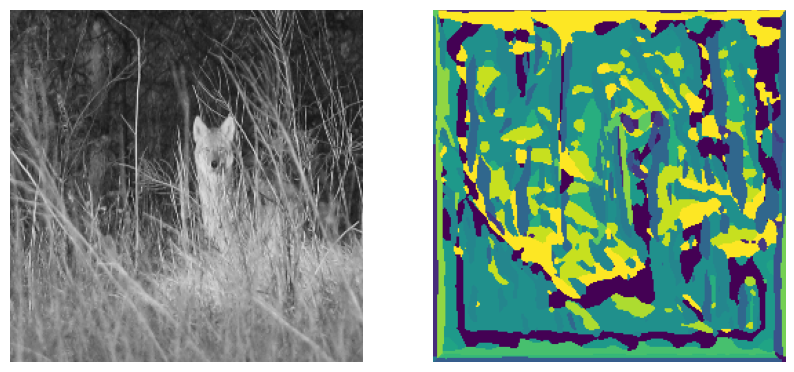

In [25]:
img=processing(cv2.imread(os.path.join(".", "dataset", "train", "Canis latrans", "f494fab00ebb2d87c8d3bf5215560d54.jpg")),  (256, 256), 'gray')
texture_img=texture_map(img,filterbank,model1)

x,y=img.shape

assert len(texture_img.shape)==2, 'Su imagen debería tener solo 2 dimensiones'
x2,y2=texture_img.shape
assert x==x2 and y==y2, 'Las dimensiones de su imagen no deberían cambiar'
assert model1.predict([filter_map(img,filterbank)[0,0,:]])==texture_img[0,0],'La predicción del pixel 0,0 es erroneo'
assert model1.predict([filter_map(img,filterbank)[24,24,:]])==texture_img[24,24],'La predicción del pixel 24,24 es erroneo'

fig,ax=plt.subplots(1,2,figsize=(10,10))
ax[0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
ax[1].imshow(texture_img)

ax[0].axis('off')
ax[1].axis('off')
plt.show()

Por último, crearemos un histograma de textones para describir la imagen, basado en las etiquetas de textones generadas por KMeans.

**Instrucciones:**

La función debe seguir los siguientes pasos:

1. Utiliza la función texture_map que implementaste previamente para crear el mapa de texturas de la imagen. Este mapa es una versión de la imagen donde cada píxel está representado por la etiqueta del clúster al que pertenece, según KMeans.

2. Una vez tengas el mapa de texturas (una imagen de 2 dimensiones con las etiquetas de los clústeres), crea un histograma utilizando la cantidad de bins especificada y de rango (0, bins-1). Este histograma contará la frecuencia de cada textón en la imagen.

3. Normaliza el histograma, de manera que la suma total de los valores sea 1. Esto permitirá comparar el histograma entre diferentes imágenes independientemente de su tamaño.

**Nota:** El histograma debe reflejar la frecuencia de aparición de cada textón (clúster) en la imagen. Asegúrate de especificar correctamente la cantidad de bins para agrupar los textones.

In [26]:
def texture_histogram(Im: np.ndarray, filterbank: np.ndarray, texton_dict: KMeans, bins: int) -> np.ndarray:
    """Funcion que calcula el histograma de textones de una imagen

    Args:
        Im (numpy.ndarray): Imagen de entrada RGB
        filterbank (numpy.ndarray): Banco de filtros
        texton_dict (KMeans): Diccionario de textones
        bins (int): Número de bins del histograma

    Returns:
        numpy.ndarray: Histograma de textones normalizado
    """
    histogram = "" # Histograma de textones normalizado
    # YOUR CODE HERE (Daniela)
    # Mapa de textones de la imagen
    texture_im = texture_map(Im, filterbank, texton_dict)

    # Se cuenta cuántas veces aparece cada textón, con rango (0, bins-1)
    histogram, _ = np.histogram(texture_im, bins=bins, range=(0, bins - 1))

    # Se normaliza para que la suma sea 1
    histogram = histogram / np.sum(histogram)
    return histogram

In [27]:
histogram_text=texture_histogram(img,filterbank,model1,textones)
assert np.isclose(np.sum(histogram_text),1), 'El histograma no esta normalizado'
assert len(histogram_text)==textones, 'El histograma no tiene la cantidad de bins que se indicó'

#### Parte 2.4: Clasificación
En esta etapa, utilizaremos nuevamente el clasificador vecino más cercano pero con los descriptores de textura. Ahora que tenemos un método para la clasificación y un método para describir nuestras imágenes mediante vectores, es momento de combinar estas dos metodologías para crear nuestro modelo de clasificación. Obtendrás el descriptor de textura usando 25 textones (el modelo KMeans que creaste anteriormente) y 25 bins.

##### Parte 2.4.1: Datos

1. Obtener descriptores de textura:

    - Extrae el descriptor de 150 imágenes en el conjunto de entrenamiento (train).
    - Extrae el descriptor de las 50 (10 de cada clase) imágenes en el conjunto de validación (valid) junto con las labels correspondientes.

2. Guardar los datos:

    - Se recomienda usar la librería pickle para guardar los descriptores y etiquetas. Esto facilitará la carga de los datos en futuros pasos.
    
3. Ajuste de tamaño:

    - Recuerda hacer un resize con la función processing de las imágenes a un tamaño de 256x256 antes de extraer los descriptores.

In [28]:
train_labels_list = [] #lista de etiquetas de entrenamiento
train_texture_desc=[] #vector de descriptores

valid_labels_list = [] #lista de etiquetas de validación
valid_texture_desc=[] #vector de descriptores
# YOUR CODE HERE (Daniela)
n_train_per_class = 30 # 30 imágenes x 5 clases = 150 de entrenamiento
n_valid_per_class = 10 # 10 imágenes x 5 clases = 50 de validación

random.seed(group) # Semilla para que siempre salgan las mismas imágenes
for name, idx in dict_labels.items():
    # Rutas de esta clase en train y en valid
    class_train = [p for p, l in zip(train_paths, train_labels) if l == idx]
    class_valid = [p for p, l in zip(valid_paths, valid_labels) if l == idx]

    # Descriptores de entrenamiento (imagen 256x256 en gris)
    for path in tqdm(random.sample(class_train, n_train_per_class), desc=f"Train {name}"):
        Im = processing(cv2.imread(path), (256, 256), "gray")
        train_texture_desc.append(texture_histogram(Im, filterbank, model1, textones))
        train_labels_list.append(idx)

    # Descriptores de validación
    for path in tqdm(random.sample(class_valid, n_valid_per_class), desc=f"Valid {name}"):
        Im = processing(cv2.imread(path), (256, 256), "gray")
        valid_texture_desc.append(texture_histogram(Im, filterbank, model1, textones))
        valid_labels_list.append(idx)

# Se guardan los descriptores y etiquetas con pickle para no tener que recalcularlos
with open("texture_descriptors.pkl", "wb") as f:
    pickle.dump({"train_desc": train_texture_desc, "train_labels": train_labels_list,
                 "valid_desc": valid_texture_desc, "valid_labels": valid_labels_list}, f)

Valid Urocyon cinereoargenteus: 100%|██████████| 10/10 [03:01<00:00, 18.10s/it]


In [29]:
assert len(valid_texture_desc[0]) == len(train_texture_desc[0]), 'Los descriptores no son de la misma dimensión'
assert len(valid_texture_desc) == len(valid_labels_list), 'Usted no cargó la cantidad correcta de etiquetas'
assert len(train_texture_desc) == len(train_labels_list), 'Usted no cargó la cantidad correcta de etiquetas'

Realiza la clasificación creando un objeto de la clase NN_classifier, entrena con .fit usando los descriptores de entrenamiento y predice los descriptores de validación con .predict.

In [30]:
predict_vector=[] #vector de etiquetas predichas
NNclassifier = '' #modelo de clasificador
# YOUR CODE HERE (Daniela)
# Clasificador K-NN entrenado con los histogramas de textones
NNclassifier = KNeighborsClassifier(n_neighbors=k)
NNclassifier.fit(train_texture_desc, train_labels_list)

# Predicción sobre los descriptores de validación
predict_vector = NNclassifier.predict(valid_texture_desc)

In [31]:
assert len(predict_vector)==len(valid_texture_desc), 'El vector de predicciones debe la misma cantidad que descriptores de validación'
assert NNclassifier.n_features_in_== 25, 'El modelo no tiene la cantidad de textones correcta'
assert NNclassifier.n_samples_fit_ == 150, 'El modelo no fue entrenado correctamente'

Finalmente, obtén las métricas de clasificación utilizando la función `precision_recall_fscore_support` de sklearn.

**Nota:** Usa average="macro" para obtener las métricas promediadas o average=None para obtenerlas para cada clase.

In [32]:
precision='' #Vector de precisión de cada categoría
recall='' #Vector de cobertura de cada categoría
f1_score='' #Vector de f medida de cada categoría
# YOUR CODE HERE (Daniela)
# Métricas por categoría (average=None) para el análisis
precision_cat, recall_cat, f1_cat, _ = precision_recall_fscore_support(
    valid_labels_list, predict_vector, average=None, zero_division=0)
for name, idx in dict_labels.items():
    print(f"{name:<28} P={precision_cat[idx]:.3f}  R={recall_cat[idx]:.3f}  F1={f1_cat[idx]:.3f}")

# Métricas promedio (macro), que son las que se comparan con las de color
precision, recall, f1_score, _ = precision_recall_fscore_support(
    valid_labels_list, predict_vector, average="macro", zero_division=0)
print(f"\nPromedio (macro): Precisión={precision:.3f}  Cobertura={recall:.3f}  F1={f1_score:.3f}")

Castor canadensis            P=0.250  R=0.500  F1=0.333
Didelphis virginiana         P=0.200  R=0.100  F1=0.133
Procyon lotor                P=0.250  R=0.200  F1=0.222
Sciurus niger                P=0.400  R=0.400  F1=0.400
Urocyon cinereoargenteus     P=0.286  R=0.200  F1=0.235

Promedio (macro): Precisión=0.277  Cobertura=0.280  F1=0.265


In [33]:
assert f1_score > 0.16, 'La f-medida no es la esperada'

### Textura forma eficiente
Cómo se pudieron dar cuenta los descriptores de textura pueden ser poco eficientes. El proceso se demora un tiempo considerable. Por lo tanto nosotros le proveeremos una función de `filter_map` que permite realizar todo el procedimiento de una manera mucho más rápida.

**Nota:** Para poder utilizar esta función de forma correcta tendrán que usar una librería llamada torch, por lo tanto le recomendamos usar Google Colab y configurar el entorno de ejecución para utilizar un GPU cómo acelerador por Hardware. El Asistente Graduado explicará esto de forma más detallada.

In [34]:
import torch

def filter_map(Im: np.ndarray, filterbank: np.ndarray) -> torch.tensor:
    """Funcion que aplica un banco de filtros a una imagen

    Args:
        Im (numpy.ndarray): Imagen de entrada RGB

    Returns:
        numpy.ndarray: Resultado de aplicar el banco de filtros a la imagen
    """
    if len(Im.shape) == 3:
        Im = cv2.cvtColor(Im, cv2.COLOR_BGR2GRAY)
        
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    dtype = torch.float32

    Im = torch.tensor(Im, dtype=dtype, device=device)
    Im = Im[None, None]
    filterbank = torch.tensor(filterbank, dtype=dtype, device=device)
    filterbank = filterbank.permute(2, 0, 1)[:, None]
    convolution = torch.nn.functional.conv2d(Im, filterbank, padding="same")
    convolution = convolution.permute(0, 2, 3, 1)
    new_im = convolution.to("cpu").numpy()[0]

    return new_im

## Entregables
Los entregables para esta primera entrega son los siguientes:

- Jupyter notebook (.ipynb): El notebook debe estar completamente resuelto. Recuerden que la nota depende del correcto funcionamiento de su código.

- Informe (.pdf): Un informe que describa lo realizado en esta entrega, incluyendo visualizaciones, análisis y otros aspectos relevantes para demostrar el desarrollo del miniproyecto. La extensión máxima del informe será de 3 páginas. No es necesario que sea muy detallado ni que siga una estructura específica, solo se solicita para verificar que hayan cumplido correctamente con el desarrollo del miniproyecto.

- Archivo de texto (.txt): Un archivo de texto con las secciones de código del Jupyter notebook. Para más información sobre cómo convertir las secciones de código de su Jupyter notebook a un archivo de texto, pueden ver el video disponible en el siguiente [enlace](https://uniandes-edu-co.zoom.us/rec/share/QOxUUIw7Uz9DsnKPyftOXZgM4bx5d7KHMYK-dqvGnkyJ2GfqvT7NU3lhQc0NtNSU.jveWB2H34S4uLIoB).

**Nota:** En esta entrega no adelantaremos las secciones del artículo. Continuaremos con el artículo la próxima entrega cuando ya tengamos un método de base.

In [35]:
from utils import *
converter("Entrega 2")

Notebook 'Entrega 2SOL.ipynb' convertido a 'Entrega 2.py'


'Entrega 2.py'

In [36]:
import shutil

# Se copia el .py generado como .txt para la entrega (Daniela)
shutil.copy("Entrega 2.py", "Entrega 2.txt")
print("Archivo generado: Entrega 2.txt")

Archivo generado: Entrega 2.txt
